# Edges, Gradients, and Gabor Texture

The color histogram of the Matterhorn photo is mostly sky blue, white, and a dark blue-gray. A
white sailboat on a lake below a blue sky could have almost the same histogram. What makes the
Matterhorn recognizable is something else: four ridges that meet in a sharp summit, dark rock
bands between fields of snow, the grain of the forest below. All of this lies in how the
intensity changes from one pixel to the next. This notebook follows the first half of the book
section *Edges, Texture, and Shape*: it computes the gradient of one pixel by hand, turns the
gradients of whole photos into edge densities and gradient histograms, and builds a bank of Gabor
filters. At the end, we send the Matterhorn photo as a query to a collection of 45 photos and
compare what color and edges find.

**Learning goals:**
- Apply the Sobel kernels by hand and read the gradient magnitude and direction of one pixel
- Compute the gradients of a whole photo and see what the threshold and the smoothing do
- Compute edge densities and gradient histograms and read them as descriptions of a photo
- Build a bank of Gabor filters and see which filter responds to which structure
- Compare color and edge features on the same query

**Prerequisites:** demo ch10-01 (Lab color space, histograms, moments, Gaussian normalization)

**Data:** the three photos of demo ch10-01 in `data/images/`. The payoff uses the collection of 45
photos from the book: 43 photos from Wikimedia Commons are downloaded on the first run (about
16 MB, cached in `data/.cache/images/ch10/`; `data/images/ch10_collection.json` lists authors and
licenses). No neural network is needed.

## Setup

Most edge features work on the brightness alone, so we use the lightness channel $L$ of CIE Lab
from demo ch10-01, with values from 0 to 100. `ch10_features.py` provides the lightness, the
Sobel kernels, and `gradients()`, which slides the kernels over every pixel with OpenCV. We
apply the kernels by hand to one pixel first.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.patches import Rectangle
from matplotlib.ticker import PercentFormatter
import cv2

from shared.display import print_table, display_md
from ch10_features import (PHOTOS, load_photos, lightness, gradients, SOBEL_X, SOBEL_Y, lab_histogram,
                           lab_similarity_matrix, quadratic, load_collection, load_image, thumbnail,
                           crop_32, show_images)

photos = load_photos()                                   # name -> sRGB pixels (height x width x 3)
titles = {name: title for name, (_, title) in PHOTOS.items()}
L = {name: lightness(p) for name, p in photos.items()}   # name -> lightness, 0 to 100

## 1. The Gradient of One Pixel

The Sobel operator estimates the rate of change of the intensity with two small kernels. To apply
a kernel at a pixel, we place it over the pixel and its eight neighbors, multiply each weight by
the pixel value under it, and sum the products:

$$\mathbf{G}_x = \frac{1}{8}\begin{bmatrix} -1 & 0 & +1 \\ -2 & 0 & +2 \\ -1 & 0 & +1 \end{bmatrix} \qquad \mathbf{G}_y = \frac{1}{8}\begin{bmatrix} -1 & -2 & -1 \\ 0 & 0 & 0 \\ +1 & +2 & +1 \end{bmatrix}$$

$g_x$ is positive where the image gets brighter to the right, $g_y$ where it gets brighter
downward, because image rows are counted from the top. The book's example is the pixel
$(x, y) = (329, 460)$ of the Matterhorn photo, where the dark rock of the mountain's left shoulder
meets the sky.

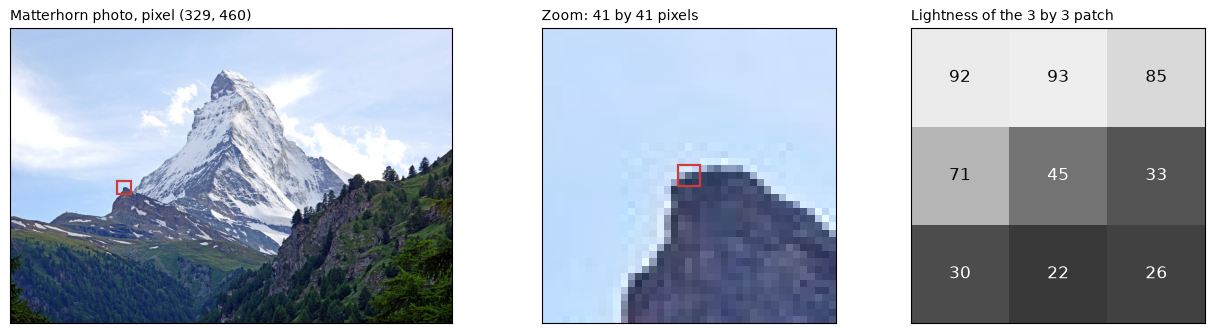

In [2]:
x, y = 329, 460
m = photos["matterhorn"]
patch = np.round(L["matterhorn"][y - 1:y + 2, x - 1:x + 2])     # the pixel and its 8 neighbors, rounded

fig, axes = plt.subplots(1, 3, figsize=(13, 3.4), gridspec_kw=dict(width_ratios=[1.5, 1, 1]))
axes[0].imshow(m)
axes[0].add_patch(Rectangle((x - 20, y - 20), 40, 40, fill=False, ec="#d03b3b", lw=1.6))
axes[0].set_title(f"Matterhorn photo, pixel ({x}, {y})", fontsize=10, loc="left")
axes[1].imshow(m[y - 20:y + 21, x - 20:x + 21], interpolation="nearest", extent=(x - 20.5, x + 20.5, y + 20.5, y - 20.5))
axes[1].add_patch(Rectangle((x - 1.5, y - 1.5), 3, 3, fill=False, ec="#d03b3b", lw=1.6))
axes[1].set_title("Zoom: 41 by 41 pixels", fontsize=10, loc="left")
axes[2].imshow(patch, cmap="gray", vmin=0, vmax=100)
for (i, j), v in np.ndenumerate(patch):
    axes[2].text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=12, color="#0b0b0b" if v > 55 else "white")
axes[2].set_title("Lightness of the 3 by 3 patch", fontsize=10, loc="left")
for ax in axes:
    ax.set_xticks([]), ax.set_yticks([])
plt.tight_layout()
plt.show()

The kernels are an elementwise product with the patch, summed. From $g_x$ and $g_y$ follow the
gradient magnitude and direction:

$$g_{\text{mag}} = \sqrt{g_x^2 + g_y^2} \qquad g_{\text{dir}} = \operatorname{atan2}(g_y, g_x)$$

In [3]:
gx_p = (patch * SOBEL_X).sum()
gy_p = (patch * SOBEL_Y).sum()
mag_p = np.hypot(gx_p, gy_p)
dir_p = np.degrees(np.arctan2(gy_p, gx_p))

display_md(f"| Quantity | Value |\n|---|---|\n"
           f"| $g_x$ (brighter to the right if positive) | {gx_p:.3f} |\n"
           f"| $g_y$ (brighter downward if positive) | {gy_p:.3f} |\n"
           f"| $g_{{\\text{{mag}}}}$ (at most 50, for a step from black to white) | {mag_p:.2f} |\n"
           f"| $g_{{\\text{{dir}}}}$ in degrees | {dir_p:.1f} |")

| Quantity | Value |
|---|---|
| $g_x$ (brighter to the right if positive) | -10.875 |
| $g_y$ (brighter downward if positive) | -32.875 |
| $g_{\text{mag}}$ (at most 50, for a step from black to white) | 34.63 |
| $g_{\text{dir}}$ in degrees | -108.3 |

The values match the book. The magnitude is high, so this is a strong edge. Since -90° points
straight up in image coordinates, the direction -108.3° points up and 18.3° to the left: from the
dark rock toward the bright sky. The edge itself runs perpendicular to the gradient and rises to
the right at 18.3°, which is the ridge that climbs toward the summit.

## 2. Gradients of a Whole Photo

`gradients()` slides both kernels over every pixel. Because the difference of neighboring pixels
amplifies noise, we first smooth the lightness with a Gaussian of one pixel width, as the book
does. The direction image shows each pixel in a color for its direction and with a brightness for
its magnitude, so flat regions stay dark.

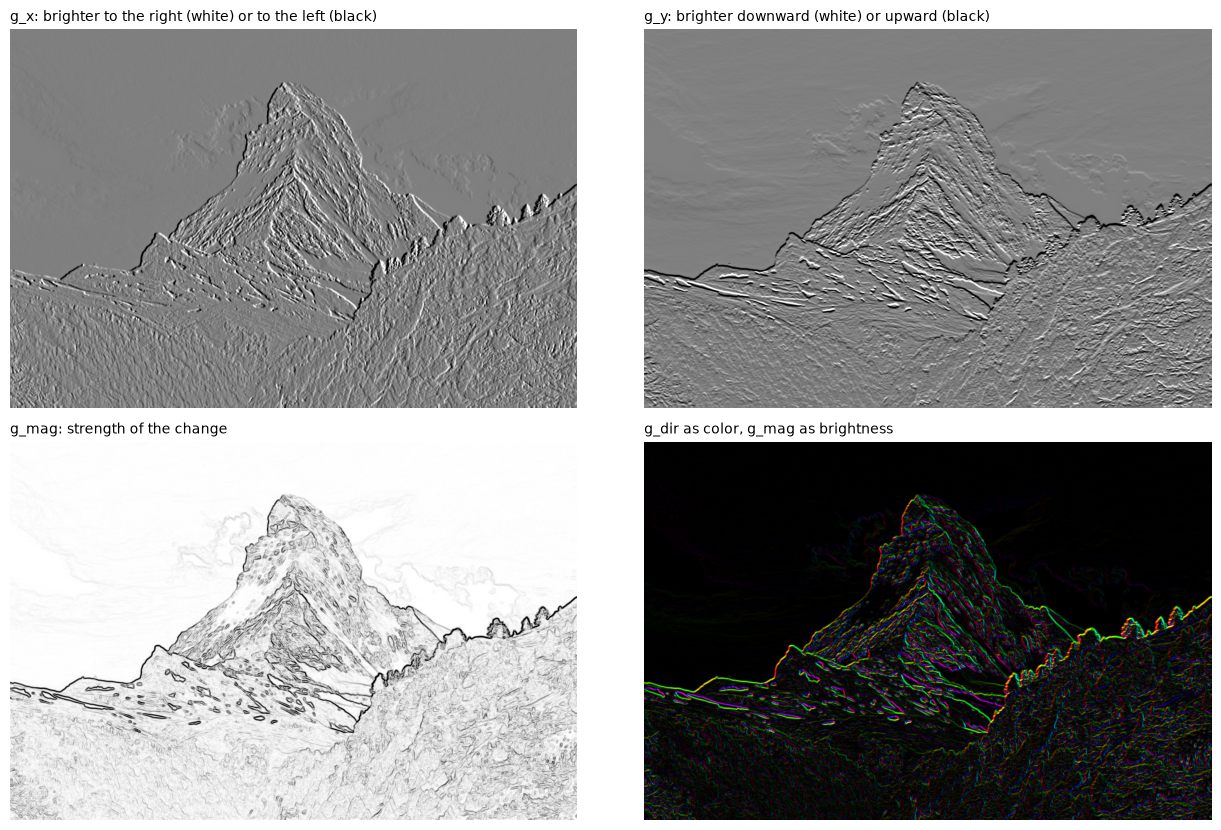

In [4]:
gx, gy = gradients(L["matterhorn"], smooth_sigma=1.0)
mag = np.hypot(gx, gy)
direction = np.degrees(np.arctan2(gy, gx))                       # -180 to 180 degrees

dir_view = mcolors.hsv_to_rgb(np.stack([(direction + 180) / 360, np.ones_like(mag), np.clip(mag / 16, 0, 1)], -1))
panels = [(gx, "g_x: brighter to the right (white) or to the left (black)", dict(cmap="gray", vmin=-8, vmax=8)),
          (gy, "g_y: brighter downward (white) or upward (black)", dict(cmap="gray", vmin=-8, vmax=8)),
          (mag, "g_mag: strength of the change", dict(cmap="gray_r", vmin=0, vmax=16)),
          (dir_view, "g_dir as color, g_mag as brightness", {})]
fig, axes = plt.subplots(2, 2, figsize=(13, 8.4))
for ax, (img, title, kw) in zip(axes.ravel(), panels):
    ax.imshow(img, **kw)
    ax.set_title(title, fontsize=10, loc="left")
    ax.axis("off")
plt.tight_layout()
plt.show()

The sky and the snow fields are flat. The ridges, the rock bands, and the trees on the right
produce strong gradients. In the direction image, the many short rock bands on the face produce
all colors, while a long straight edge, such as the line of the forest on the right, keeps one
color along its length.

## 3. Edge Density

A pixel is an **edge pixel** if its gradient magnitude reaches a threshold $\tau$. The **edge
density** is the share of edge pixels:

$$f_{\text{edge}} = \frac{1}{NM} \sum_{x,y} \mathbb{1}\big[g_{\text{mag}}(x,y) \geq \tau\big]$$

The book uses $\tau = 4$ after smoothing with a Gaussian of one pixel width. The threshold stays
the same for all images, so that their edge densities can be compared.

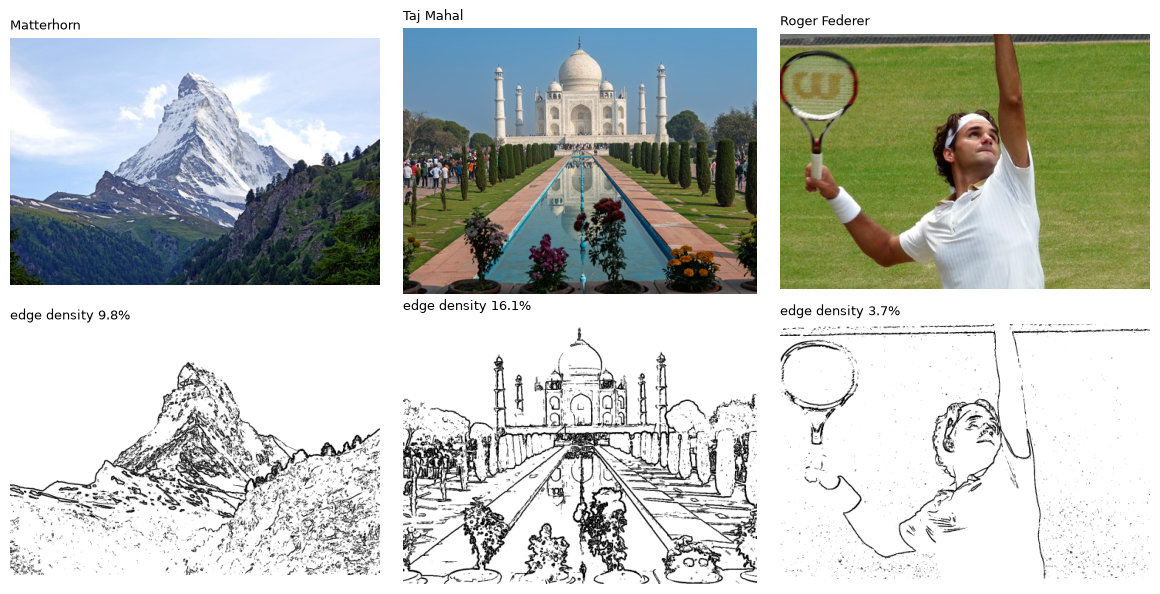

In [5]:
TAU, SIGMA = 4.0, 1.0

def edge_map(L_img, tau=TAU, sigma=SIGMA):
    gx, gy = gradients(L_img, smooth_sigma=sigma)
    return np.hypot(gx, gy) >= tau

edges = {n: edge_map(l) for n, l in L.items()}

def edge_view(e, longest=480):
    """Edge pixels in black; the downscaled view averages the area, so dense edges stay dark."""
    im = cv2.resize((~e).astype(np.float32), None, fx=longest / max(e.shape), fy=longest / max(e.shape),
                    interpolation=cv2.INTER_AREA)
    return np.stack([im] * 3, -1)

show_images([thumbnail(p) for p in photos.values()] + [edge_view(e) for e in edges.values()],
            list(titles.values()) + [f"edge density {e.mean():.1%}" for e in edges.values()], ncols=3)

The Taj Mahal photo, with its architecture, visitors, and trees, has the most edge pixels. The
Matterhorn photo follows, mostly from its ridges, rock bands, and forest. The Federer photo has
few: the lawn and the slightly blurred background are smooth, and its edge pixels lie on the
outline of the player and the racket, on a long line at the top, and in scattered dots in the
grass.

The threshold and the smoothing decide what counts as an edge. Without smoothing, noise and fine
grain cross the threshold too:

In [6]:
rows = []
for sigma in (None, 1.0):
    for tau in (2.0, 4.0, 8.0):
        rows.append([("no smoothing" if sigma is None else f"Gaussian, {sigma:g} pixel"), tau]
                    + [edge_map(l, tau, sigma).mean() for l in L.values()])
print_table(rows, headers=["Smoothing", "Threshold tau"] + [f"Edge density, {t}" for t in titles.values()],
            floatfmt=("", ".0f", ".1%", ".1%", ".1%"))

| Smoothing         |   Threshold tau |   Edge density, Matterhorn |   Edge density, Taj Mahal |   Edge density, Roger Federer |
|:------------------|----------------:|---------------------------:|--------------------------:|------------------------------:|
| no smoothing      |               2 |                      37.0% |                     41.3% |                         39.3% |
| no smoothing      |               4 |                      20.3% |                     25.0% |                         11.5% |
| no smoothing      |               8 |                       7.2% |                     11.1% |                          1.5% |
| Gaussian, 1 pixel |               2 |                      24.6% |                     31.0% |                         17.0% |
| Gaussian, 1 pixel |               4 |                       9.8% |                     16.1% |                          3.7% |
| Gaussian, 1 pixel |               8 |                       2.5% |                      5.1% |                          0.8% |

The densities change a lot with both settings. Without smoothing and with a low threshold, the
grain of the lawn counts as edges almost everywhere, and the Federer photo overtakes the
Matterhorn photo. With smoothing, the order of the three photos stays the same for all three
thresholds. A single number per photo is a coarse feature in any case: it says how busy a photo
is, not what the busy parts look like.

## 4. Gradient Histograms

A **gradient histogram** works like a color histogram, with reference gradients in place of
reference colors. The book divides the directions into $K = 8$ sectors of 45°, centered on 0°,
45°, and so on, and the magnitudes from $\tau$ upward into $J = 3$ ranges: from 4 to 8, from 8 to
16, and from 16 upward. Each pair of a sector and a range is one of $8 \cdot 3 = 24$ reference
gradients. The histogram counts only the edge pixels, because in a flat region the direction of a
tiny gradient is mostly noise, just like the hue of a gray pixel.

$$h_{k,j} = \frac{1}{|E|} \sum_{(x,y) \in E} \mathbb{1}\big[g_{\text{dir}}(x,y) \in D_k \text{ and } g_{\text{mag}}(x,y) \in R_j\big]$$

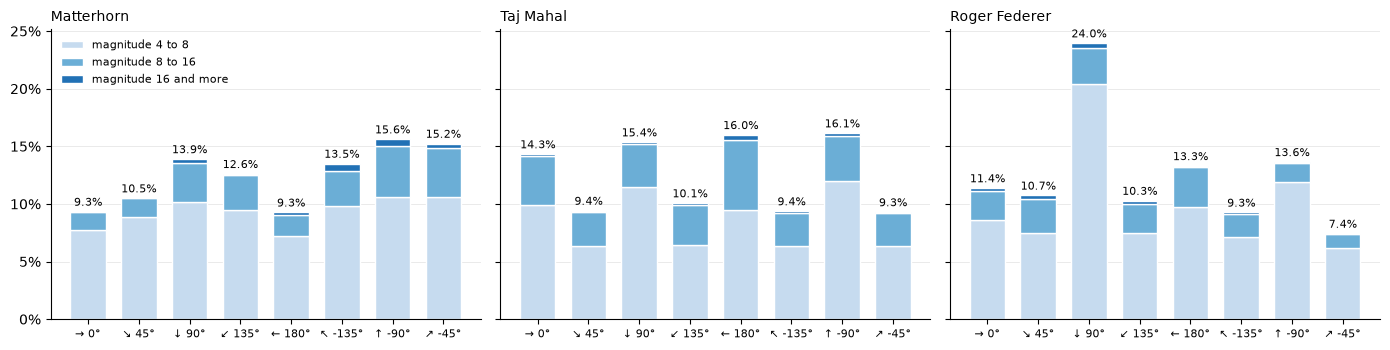

In [7]:
DIRECTIONS = ["→ 0°", "↘ 45°", "↓ 90°", "↙ 135°", "← 180°", "↖ -135°", "↑ -90°", "↗ -45°"]
MAG_RANGES = ["4 to 8", "8 to 16", "16 and more"]

def gradient_histogram(L_img, tau=TAU, sigma=SIGMA):
    """8 x 3 histogram of the edge pixels: direction sector (rows) by magnitude range (columns)."""
    gx, gy = gradients(L_img, smooth_sigma=sigma)
    mag = np.hypot(gx, gy)
    edge = mag >= tau
    k = np.round(np.degrees(np.arctan2(gy, gx)) / 45).astype(int) % 8    # sector centered on k * 45 degrees
    j = np.digitize(mag, [2 * tau, 4 * tau])                             # magnitude range 0, 1, or 2
    h = np.zeros((8, 3))
    np.add.at(h, (k[edge], j[edge]), 1)
    return h / edge.sum()

GH = {n: gradient_histogram(l) for n, l in L.items()}

blues = ["#c6dbef", "#6baed6", "#2171b5"]          # weak to strong edges
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for ax, (n, h) in zip(axes, GH.items()):
    bottom = np.zeros(8)
    for j in range(3):
        ax.bar(range(8), h[:, j], bottom=bottom, width=0.7, color=blues[j], edgecolor="white", linewidth=1,
               label=f"magnitude {MAG_RANGES[j]}")
        bottom += h[:, j]
    for i, v in enumerate(bottom):
        ax.text(i, v + 0.005, f"{v:.1%}", ha="center", fontsize=8)
    ax.set_xticks(range(8), DIRECTIONS, fontsize=8)
    ax.set_title(titles[n], fontsize=10, loc="left")
    ax.yaxis.set_major_formatter(PercentFormatter(1.0, decimals=0))
    ax.spines[["top", "right"]].set_visible(False)
    ax.grid(axis="y", color="#e6e6e6", lw=0.6)
    ax.set_axisbelow(True)
axes[0].legend(fontsize=8, frameon=False, loc="upper left")
plt.tight_layout()
plt.show()

The arrows show where the image gets brighter. The table sums the histograms in the way the book
reads them: the four sectors along the image axes against the four diagonal ones, and the share
of the weakest magnitude range.

In [8]:
axis_aligned, diagonal = [0, 2, 4, 6], [1, 3, 5, 7]
print_table([[titles[n], h[axis_aligned].sum(), h[diagonal].sum(), DIRECTIONS[h.sum(1).argmax()], h.sum(1).max(),
              h[:, 0].sum()] for n, h in GH.items()],
            headers=["Photo", "Along the axes (0°, 90°, 180°, -90°)", "Diagonal", "Largest sector", "Its share",
                     "Weakest range (4 to 8)"],
            floatfmt=".1%")

| Photo         |   Along the axes (0°, 90°, 180°, -90°) |   Diagonal | Largest sector   |   Its share |   Weakest range (4 to 8) |
|:--------------|---------------------------------------:|-----------:|:-----------------|------------:|-------------------------:|
| Matterhorn    |                                  48.1% |      51.9% | ↑ -90°           |       15.6% |                    74.4% |
| Taj Mahal     |                                  61.8% |      38.2% | ↑ -90°           |       16.1% |                    68.4% |
| Roger Federer |                                  62.3% |      37.7% | ↓ 90°            |       24.0% |                    79.0% |

In the Taj Mahal photo, the vertical lines of the minarets and the horizontal lines of the walls
and the pool produce gradients along the image axes. The ridges and slopes of the Matterhorn are
diagonal, so its edge pixels split almost evenly between the axis-aligned and the diagonal
sectors. The largest bar of the Federer photo, at 90°, comes from a single long line: the edge
between the dark border at the top of the photo and the brighter lawn below it. In all three
photos, most edge pixels fall into the weakest magnitude range. The values match the book.

## 5. Texture with Gabor Filters

A texture is a pattern of intensity changes that repeats over a region: the stripes of tree
trunks, the ripples on a lake, the grid of windows on a facade. The 3 by 3 Sobel kernels respond
to a single scale of change. A **Gabor filter** responds to one wavelength and one orientation: it
is a sinusoidal wave inside a Gaussian window, defined on the rotated coordinates
$\bar{x} = x \cos\theta + y \sin\theta$ and $\bar{y} = -x \sin\theta + y \cos\theta$:

$$g_{\lambda,\theta,\phi,\sigma,\gamma}(x, y) = \exp\left(-\frac{\bar{x}^2 + \gamma^2 \bar{y}^2}{2\sigma^2}\right) \cdot \exp\left(i \left(2\pi \frac{\bar{x}}{\lambda} + \phi\right)\right)$$

The wave runs along $\bar{x}$, so its stripes are perpendicular to the angle $\theta$: a filter
with $\theta = 0°$ responds to vertical stripes and edges, a filter with $\theta = 90°$ to
horizontal ones. The book leaves the parameters open; typical banks use 3 to 7 orientations and
frequencies $1/\lambda$ between about 0.05 and 0.5 cycles per pixel. We use the bank of the
book's example: 5 orientations (0°, 36°, 72°, 108°, 144°) and 3 wavelengths (4, 8, and 16
pixels, so frequencies of 0.25, 0.125, and 0.0625), with a window width $\sigma = 0.56 \lambda$
and an aspect ratio $\gamma = 0.5$ (our choices). The phase does not matter, because we use the
absolute value of the complex response.

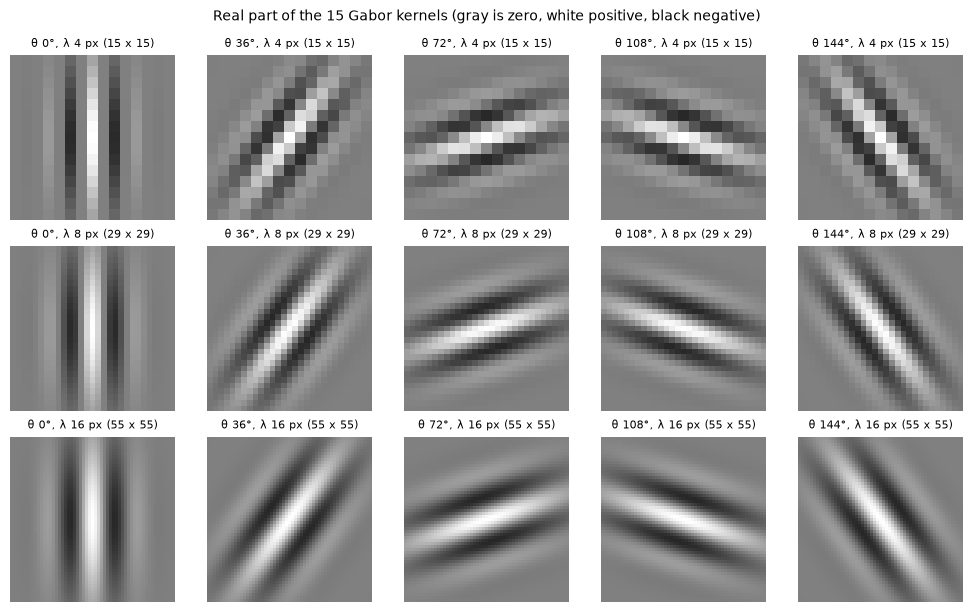

In [9]:
def gabor_kernel(theta_deg, lam, gamma=0.5, phase=0.0):
    """Complex Gabor kernel with wavelength lam (pixels) and orientation theta; window width 0.56 lam."""
    sigma = 0.56 * lam
    r = int(np.ceil(3 * sigma))
    yy, xx = np.mgrid[-r:r + 1, -r:r + 1].astype(float)
    t = np.radians(theta_deg)
    xb = xx * np.cos(t) + yy * np.sin(t)
    yb = -xx * np.sin(t) + yy * np.cos(t)
    return np.exp(-(xb ** 2 + gamma ** 2 * yb ** 2) / (2 * sigma ** 2)) * np.exp(1j * (2 * np.pi * xb / lam + phase))

ORIENTATIONS, WAVELENGTHS = (0, 36, 72, 108, 144), (4, 8, 16)
BANK = [(theta, lam) for lam in WAVELENGTHS for theta in ORIENTATIONS]

fig, axes = plt.subplots(3, 5, figsize=(10, 6.2))
for ax, (theta, lam) in zip(axes.ravel(), BANK):
    k = gabor_kernel(theta, lam).real
    ax.imshow(k, cmap="gray", vmin=-1, vmax=1, interpolation="nearest")
    ax.set_title(f"θ {theta}°, λ {lam} px ({k.shape[0]} x {k.shape[1]})", fontsize=8)
    ax.axis("off")
plt.suptitle("Real part of the 15 Gabor kernels (gray is zero, white positive, black negative)", fontsize=10)
plt.tight_layout()
plt.show()

Each filter produces a complex response image, and its absolute value measures how strongly the
filter's pattern is present at each pixel. The Taj Mahal photo has strong vertical structures
(the minarets, the cypress trees) and strong horizontal ones (the walls, the edges of the pool).
The bank has no filter at exactly 90°, so for this comparison we compute one extra filter at 90°
next to the one at 0°, both with a wavelength of 8 pixels.

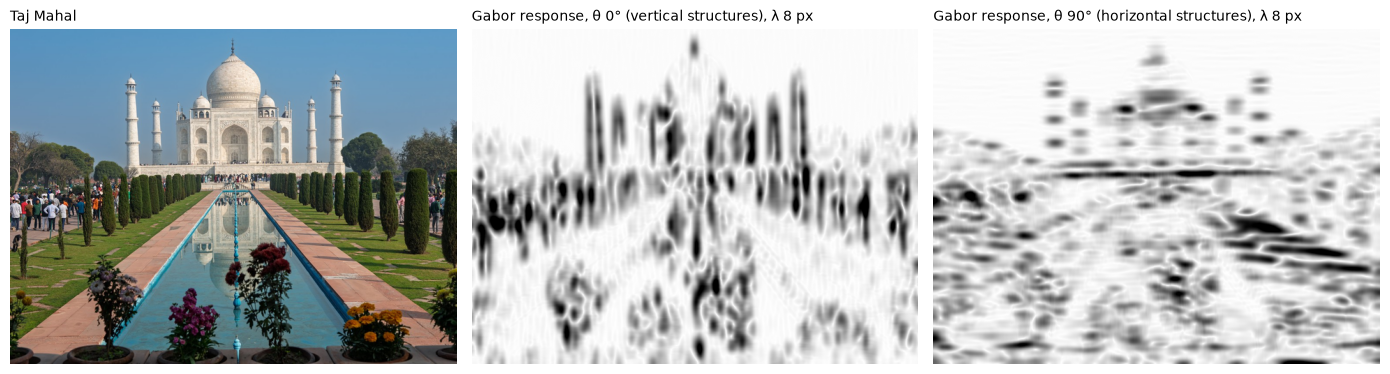

In [10]:
def gabor_response(L_img, theta, lam):
    """Absolute value of the complex response: strength of the filter's pattern at each pixel."""
    k = gabor_kernel(theta, lam)
    re = cv2.filter2D(L_img, -1, k.real.astype(np.float32), borderType=cv2.BORDER_REFLECT)
    im = cv2.filter2D(L_img, -1, k.imag.astype(np.float32), borderType=cv2.BORDER_REFLECT)
    return np.hypot(re, im)

taj = lightness(thumbnail(photos["taj_mahal"], 640))
resp = {theta: gabor_response(taj, theta, 8) for theta in (0, 90)}
vmax = max(r.max() for r in resp.values())
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
axes[0].imshow(thumbnail(photos["taj_mahal"], 640))
axes[0].set_title("Taj Mahal", fontsize=10, loc="left")
for ax, (theta, r) in zip(axes[1:], resp.items()):
    ax.imshow(r, cmap="gray_r", vmin=0, vmax=vmax * 0.6)
    ax.set_title(f"Gabor response, θ {theta}° ({'vertical' if theta == 0 else 'horizontal'} structures), λ 8 px",
                 fontsize=10, loc="left")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.show()

The filter at 0° shows the minarets, the edges of the main building, and the cypress trees as
dark vertical bands. The filter at 90° shows the long horizontal line of the terrace below the
building and the horizontal structures of the garden and the flower pots in front. This is the image counterpart of the windsurfer example in the book, where
the filters with the orientation of the mast show the mast and the others do not.

### From responses to a feature vector

To turn the 15 response images into a feature vector, we compute the four moments of demo
ch10-01 for each response image: mean, standard deviation, skewness, and kurtosis. To keep the
computation fast, we apply the bank to a copy of the photo whose longest side is 640 pixels.

In [11]:
def gabor_moments(rgb, longest=640, with_covariances=False):
    """Four moments of each of the 15 response images (60 values), optionally plus their 105 covariances."""
    L_img = lightness(thumbnail(rgb, longest))
    R = np.array([gabor_response(L_img, theta, lam).ravel() for theta, lam in BANK])    # 15 x pixels
    mu, sd = R.mean(1), R.std(1)
    z = (R - mu[:, None]) / sd[:, None]
    feats = np.column_stack([mu, sd, (z ** 3).mean(1), (z ** 4).mean(1)]).ravel()
    if with_covariances:
        C = np.cov(R, bias=True)
        feats = np.concatenate([feats, C[np.triu_indices(len(BANK), k=1)]])
    return feats

GM = {n: gabor_moments(p) for n, p in photos.items()}
display_md(f"Gabor moment vector: **{len(GM['matterhorn'])} values** "
           f"(15 filters x 4 moments); with the covariances between all pairs of response images: "
           f"**{len(gabor_moments(photos['matterhorn'], with_covariances=True))} values**.")

Gabor moment vector: **60 values** (15 filters x 4 moments); with the covariances between all pairs of response images: **165 values**.

The sizes match the book's example: 60 values, or 165 with the covariances. A joint histogram over
15 responses would need an impractical number of bins, which is why texture features use moments.

## Payoff: What Edges See That Color Misses

The book introduces a collection of 45 photos at the end of the section: 8 photos of the
Matterhorn from other positions, seasons, and light, 12 other snow-covered peaks, 9 scenes with
the colors of the query but no mountain (sailboats on a lake, chapels below forested hills), and
16 unrelated photos, including the Taj Mahal and Federer photos. We send the Matterhorn photo as
a query and rank the collection three times: by the quadratic distance of the 125-bin Lab
histograms (demo ch10-01), by the L1 distance of the gradient histograms, and by the Euclidean
distance of the 60 Gabor moments after Gaussian normalization over the collection.

In [12]:
collection = load_collection()
ids = [it["id"] for it in collection]
query = photos["matterhorn"]                     # 1280 pixels wide, like the photos of the collection

def features(rgb):
    return dict(color=lab_histogram(rgb), grad=gradient_histogram(lightness(rgb)).ravel(), gabor=gabor_moments(rgb))

Fq = features(query)
F = [features(np.asarray(load_image(it["path"]))) for it in collection]

A = lab_similarity_matrix()
gabor_scale = np.std([f["gabor"] for f in F], axis=0)
distances = {
    "Color histogram (Lab, quadratic)": np.array([quadratic(Fq["color"], f["color"], A) for f in F]),
    "Gradient histogram (L1)": np.array([np.abs(Fq["grad"] - f["grad"]).sum() for f in F]),
    "Gabor moments (normalized)": np.array([np.linalg.norm((Fq["gabor"] - f["gabor"]) / gabor_scale) for f in F]),
}
display_md(f"Collection: **{len(collection)} photos**, of which {sum(it['is_matterhorn'] for it in collection)} "
           f"show the Matterhorn and {sum(it['is_mountain'] for it in collection)} a mountain.")

Collection: **45 photos**, of which 8 show the Matterhorn and 20 a mountain.

We measure the precision at 5 at two levels of relevance: a result shows the Matterhorn, or, more
generously, any mountain. We also report the rank of the photo from nearly the same spot in
Zermatt and the best rank of a color decoy.

In [13]:
def rank_of(d, i):
    return 1 + int((d < d[i]).sum())

zermatt = ids.index("matterhorn_zermatt")
decoys = [i for i, it in enumerate(collection) if it["group"] == "color_decoy"]
rows = []
for name, d in distances.items():
    top = np.argsort(d, kind="stable")[:5]
    best_decoy = min(decoys, key=lambda i: d[i])
    rows.append([name, sum(collection[i]["is_matterhorn"] for i in top) / 5, sum(collection[i]["is_mountain"] for i in top) / 5,
                 rank_of(d, zermatt), f"{rank_of(d, best_decoy)} ({ids[best_decoy]})"])
print_table(rows, headers=["Feature", "P@5 Matterhorn", "P@5 mountain", "Rank of the photo from Zermatt",
                           "Best rank of a color decoy"], floatfmt=".1f")

| Feature                          |   P@5 Matterhorn |   P@5 mountain |   Rank of the photo from Zermatt | Best rank of a color decoy      |
|:---------------------------------|-----------------:|---------------:|---------------------------------:|:--------------------------------|
| Color histogram (Lab, quadratic) |              0.2 |            0.8 |                               26 | 5 (decoy_lake_clouds)           |
| Gradient histogram (L1)          |              0.2 |            0.8 |                                2 | 5 (decoy_lake_trees_reflection) |
| Gabor moments (normalized)       |              0.6 |            0.6 |                                6 | 2 (decoy_sailboats_aasee)       |

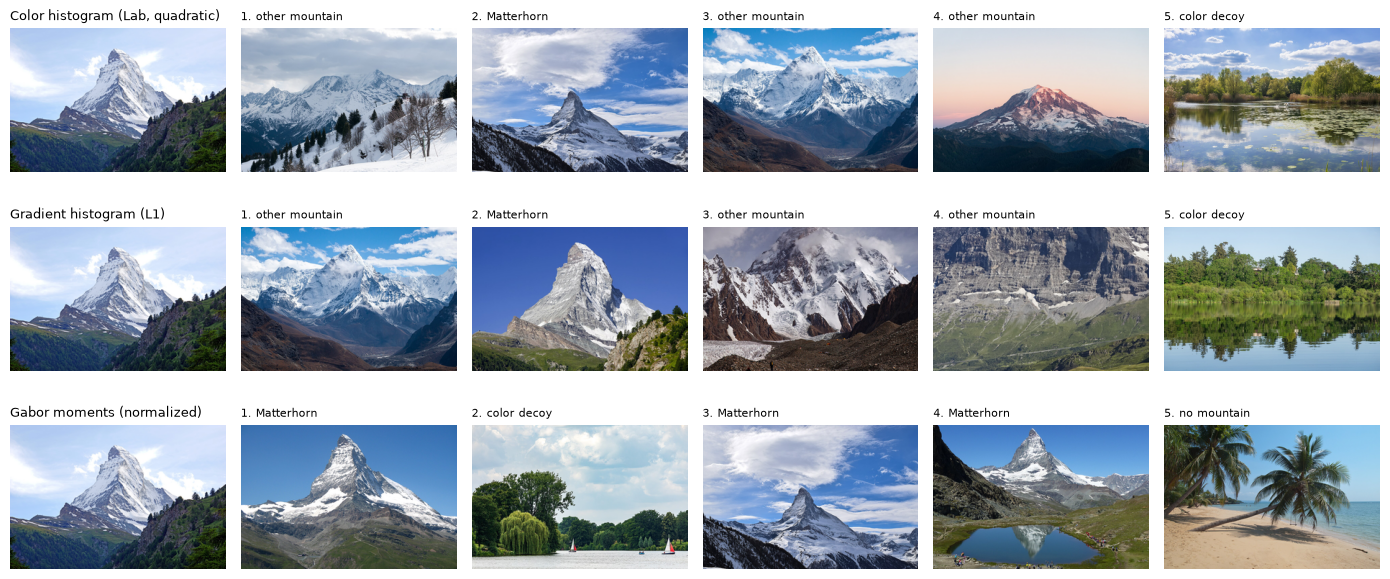

In [14]:
def mark(it):
    return "Matterhorn" if it["is_matterhorn"] else "other mountain" if it["is_mountain"] else \
           "color decoy" if it["group"] == "color_decoy" else "no mountain"

fig, axes = plt.subplots(len(distances), 6, figsize=(14, 2.1 * len(distances)))
for r, (name, d) in enumerate(distances.items()):
    axes[r, 0].imshow(crop_32(query))
    axes[r, 0].set_title(name, fontsize=9, loc="left")
    for c, i in enumerate(np.argsort(d, kind="stable")[:5], 1):
        axes[r, c].imshow(crop_32(load_image(collection[i]["path"], 480)))
        axes[r, c].set_title(f"{c}. {mark(collection[i])}", fontsize=8, loc="left")
for ax in axes.ravel():
    ax.axis("off")
plt.tight_layout()
plt.show()

The color histogram ranks the Zermatt photo far down, because its sky is a deeper blue than the
pale sky of the query. The gradient histogram puts it near the top: the edges of the ridges and
rock bands did not change. The Gabor moments find three other Matterhorn photos among their top
5, more than the two histograms, but their second result is the scene with sailboats, and their
fifth a beach with palm trees: they respond to the mix of fine and coarse structures, and other
scenes can have the same mix. Edges and textures describe how a photo looks, not what it shows.

<div style="border-left: 4px solid #C8102E; background: rgba(200, 16, 46, 0.06); padding: 0.6em 0.9em; margin: 0.6em 0; border-radius: 4px;">
<strong style="color:#C8102E; text-transform:uppercase; font-size:0.78em; letter-spacing:0.06em;">Edges describe how intensity is arranged, not what it shows</strong><br>
The gradient histogram finds the photo from nearly the same spot that the color histogram missed, because the ridges look the same under a different sky. But neither edges nor textures separate mountains from scenes with similar structure. The next demo turns to shape and to SIFT, which finds the same scene again; demo ch10-04 turns to learned features, which find mountains in general.
</div>

## Summary

- The Sobel kernels estimate the gradient from a pixel and its eight neighbors. The magnitude
  says how strong the change is, the direction where the image gets brighter; the edge runs
  perpendicular to it.
- Smoothing and the threshold $\tau$ decide which pixels count as edges. They must stay the same
  for all images of a collection.
- The edge density is a single number per photo. The gradient histogram describes the direction
  and strength of the edges, like a color histogram describes the colors, and it also ignores
  where the edges lie.
- A Gabor filter responds to stripes of one wavelength and orientation. A bank of 15 filters with
  four moments per response gives a 60-dimensional texture vector.
- On the Matterhorn query, edges find the same view under a different sky, which color misses,
  but no edge or texture feature knows the category "mountain".

## Try it yourself

1. **Threshold and smoothing.** Rerun the payoff with `TAU = 8` or `SIGMA = 2`. Which photos move,
   and does the Zermatt photo keep its rank?
2. **A different bank.** Use 3 or 7 orientations, or the wavelengths (3, 6, 12, 24), and rerun the
   payoff. How do the rank of the Zermatt photo and the best rank of a decoy change?
3. **A quadratic distance for gradients.** The book notes that the quadratic distance works for
   gradient histograms too. Build a 24 x 24 matrix $\mathbf{A}$ whose entries fall with the
   angle between two sectors (remember that angles wrap around) and with the difference of their
   magnitude ranges, and compare the ranking with the L1 distance.